In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import lightgbm as lgb
import warnings, random
warnings.filterwarnings("ignore")

seed = 1
random.seed(seed)
np.random.seed(seed)

df = pd.read_csv('SE5.csv')
forward_test_df = pd.read_csv('SE5-2.csv')
df['Time'] = pd.to_datetime(df['Time'])
forward_test_df['Time'] = pd.to_datetime(forward_test_df['Time'])
df = df.sort_values(by='Time', ascending=True)
forward_test_df = forward_test_df.sort_values(by='Time', ascending=True)
train_val_df = df[df["Time"] < "2024-01-01"]
test_df = df[df["Time"] >= "2024-01-01"]
macro_level_features = np.loadtxt('macro_level_features.txt', dtype='O')

print(f"Train/Validation data shape: {train_val_df.shape}")
print(f"Test data shape: {test_df.shape}")
print(f"Forward Test data shape: {forward_test_df.shape}")

Train/Validation data shape: (40884, 717)
Test data shape: (2313, 717)
Forward Test data shape: (1182, 717)


In [2]:
def preprocess_data_for_clustering(df_segment):
    df_segment_copy = df_segment.copy()
    if not isinstance(df_segment_copy.index, pd.DatetimeIndex):
        df_segment_copy.set_index('Time', inplace=True)
        df_segment_copy = df_segment_copy.sort_index()
        df_segment_copy = df_segment_copy[macro_level_features]
    return df_segment_copy

## Market Regime Identification

In [ ]:
# Finding the optimal regime (Elbow Analysis)
# data_for_clustering = train_val_df[macro_level_features]
# sse = dict()
# ks = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
# for k in ks:
#     km = KMeans(n_clusters=k, random_state=1)
#     km.fit_transform(data_for_clustering)
#     sse[k] = km.inertia_
# plt.plot(sse.keys(), sse.values(), marker='o')
# plt.title("Elbow Method - Optimal Market Regime Detection\n")
# plt.xlabel("Number of Clusters (Market Regimes)")
# plt.ylabel('Clustering Error (Inertia)')
# plt.show()

In [ ]:
# Predicting Regime labels and training classifier on the whole data (globally)

# data_for_clustering = preprocess_data_for_clustering(train_val_df)
# train_dfc = data_for_clustering[:32500] # ~80%, 20%
# valid_dfc = data_for_clustering[32501:] 
# print(train_dfc.shape, valid_dfc.shape)

# km = KMeans(n_clusters=4, random_state=1)
# km.fit(train_dfc)

# train_labels = km.predict(train_dfc)
# train_dfc['Regime'] = train_labels
# valid_labels = km.predict(valid_dfc)
# valid_dfc['Regime'] = valid_labels
# X = pd.concat([train_dfc, valid_dfc], ignore_index=True).drop(columns='Regime')
# y = pd.concat([train_dfc, valid_dfc], ignore_index=True)['Regime']
# x_tr, y_tr = train_dfc.drop(columns='Regime'), train_dfc['Regime']
# x_va, y_va = valid_dfc.drop(columns='Regime'), valid_dfc['Regime']
# regime_model = lgb.LGBMClassifier(objective='multiclass',class_weight='balanced',num_class=4,random_state=seed,learning_rate=0.05,n_estimators=100,n_jobs=-1,verbose=-1)

# tscv = TimeSeriesSplit(n_splits=5)
# regime_model.fit(x_tr,y_tr,# eval_set=[(X_regime_valid, y_regime_valid)], eval_metric="multi_logloss",callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=True)]
# )

# pred_regime_valid = regime_model.predict(x_va)
# print('Valid Accuracy:', accuracy_score(y_va, pred_regime_valid))

# cv_scores = cross_val_score(regime_model, X, y, scoring="balanced_accuracy", cv=tscv)
# print('Mean CV Score:', np.mean(cv_scores))

In [3]:
# Predicting Regime labels and training classifier using cross validation

tscv = TimeSeriesSplit(n_splits=5)
data_for_clustering = preprocess_data_for_clustering(train_val_df)
data_for_clustering_arr = data_for_clustering.values
fixed_centroids = None
for fold, (train_idx, valid_idx) in enumerate(tscv.split(data_for_clustering_arr)):

    """
    In below we will fit KMeans in the first fold and call it 'kmeans0' and save its centriods then predict labels
    starting second iteration Kmeans will be fitted again with the saved centriods and call it 'kmeans1'

    kmeans0 will be used to predict train and validation labels in the first fold
    kmeans0 to predict train only starting the 2nd fold while kmeans1 will be used to predict validation labels.
    """

    if fold == 0:
        kmeans0 = KMeans(n_clusters=4, random_state=1)
        kmeans0.fit(data_for_clustering_arr[train_idx])
        fixed_centroids = kmeans0.cluster_centers_
        
        labels_train = kmeans0.predict(data_for_clustering_arr[train_idx])
        labels_valid = kmeans0.predict(data_for_clustering_arr[valid_idx])
    else:
        # Subsequent folds - use fixed centroids
        kmeans1 = KMeans(n_clusters=4, init=fixed_centroids, n_init=1)
        kmeans1.fit(data_for_clustering_arr[train_idx])  # This will keep centroids fixed (n_init=1)

        # Predict and save labels for training using kmeans0, and for validation using kmeans1
        labels_train = kmeans0.predict(data_for_clustering_arr[train_idx])
        labels_valid = kmeans1.predict(data_for_clustering_arr[valid_idx])

    x_train = data_for_clustering_arr[train_idx]
    x_valid = data_for_clustering_arr[valid_idx]

    y_train = labels_train
    y_valid = labels_valid

    regime_model = lgb.LGBMClassifier(objective='multiclass',class_weight='balanced',num_class=4,random_state=seed,learning_rate=0.05,n_estimators=100,n_jobs=-1,verbose=-1)
    regime_model.fit(x_train, y_train)

    pred = regime_model.predict(x_valid)
    acc = accuracy_score(y_valid, pred)
    print(f'Fold {fold + 1} | Accuracy: {acc}')

Fold 1 | Accuracy: 0.9977986498385677
Fold 2 | Accuracy: 0.9901673026122688
Fold 3 | Accuracy: 0.9906075726445553
Fold 4 | Accuracy: 0.9863516289991194
Fold 5 | Accuracy: 0.9913413560316995


In [4]:
# Predicting regime label using LGBM classifier and add it to the full data (before 2024)
train_val_df['Regime'] = regime_model.predict(data_for_clustering)

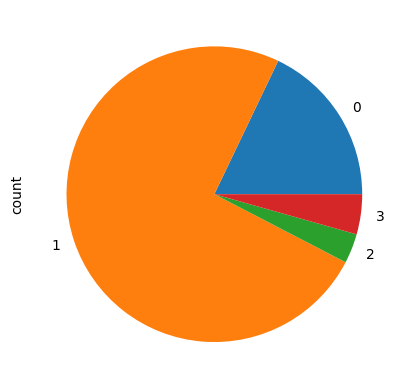

Regime
0    0.178921
1    0.744937
2    0.032360
3    0.043782
Name: proportion, dtype: float64

In [8]:
train_val_df['Regime'].value_counts().sort_index().plot(kind='pie')
plt.show()
train_val_df['Regime'].value_counts(normalize=True).sort_index()

In [ ]:
# Extracting training data
train_val_df[train_val_df['Regime']==0].to_csv('subset_r0.csv', index=False)
train_val_df[train_val_df['Regime']==1].to_csv('subset_r1.csv', index=False)
train_val_df[train_val_df['Regime']==2].to_csv('subset_r2.csv', index=False)
train_val_df[train_val_df['Regime']==3].to_csv('subset_r3.csv', index=False)

In [ ]:
# Predict regime labels on test data 2024 & adding labels
test_df_regime_labels = kmeans1.predict(test_df[macro_level_features])
test_df['Regime'] = test_df_regime_labels


# exporting as csv
test_df[test_df['Regime']==0].to_csv('test_r0.csv', index=False)
test_df[test_df['Regime']==1].to_csv('test_r1.csv', index=False)
test_df[test_df['Regime']==2].to_csv('test_r2.csv', index=False)
test_df[test_df['Regime']==3].to_csv('test_r3.csv', index=False)

In [ ]:
# Predict regime labels on forward test data 2025 & adding labels 
forward_test_df_regime_labels = kmeans1.predict(forward_test_df[macro_level_features])
forward_test_df['Regime'] = forward_test_df_regime_labels


# exporting as csv
forward_test_df[forward_test_df['Regime']==0].to_csv('forward_test_r0.csv', index=False)
forward_test_df[forward_test_df['Regime']==1].to_csv('forward_test_r1.csv', index=False)
forward_test_df[forward_test_df['Regime']==2].to_csv('forward_test_r2.csv', index=False)
forward_test_df[forward_test_df['Regime']==3].to_csv('forward_test_r3.csv', index=False)